<table style="width:100%">
  <tr>
    <td align="left">
      <img src="université-Ibn-Tofail-de-Kénitra.png" alt="Logo Université" width="190"/>
    </td>
</table>

<center><h2 style="color:#023182;text-transform: uppercase;font-family:algerian;font-size:30px"> Prédiction du Churn des Utilisateurs pour Waze </h2></center>

<hr style="border:2px solid black">

# *Introduction*

***L’Analyse Exploratoire des Données***  (EDA) est une étape clé dans tout processus d’analyse de données. Elle permet de mieux comprendre la structure, la qualité et les caractéristiques d’un jeu de données avant d’appliquer des modèles prédictifs ou d’en tirer des conclusions.
À travers des statistiques descriptives et des visualisations graphiques, l’EDA aide à détecter les valeurs manquantes, les outliers, les corrélations entre variables, ainsi que les éventuelles anomalies ou tendances cachées.



# *Objectif*

Dans le cadre de notre projet, nous étudions un dataset relatif au comportement des utilisateurs d’un service, dans le but de prédire le churn (abandon du service). L’objectif de cette analyse est de comprendre quelles variables influencent le plus la décision d’un utilisateur de rester ou quitter le service. Pour cela, nous allons explorer à la fois les variables numériques et catégorielles, analyser leur distribution, leur relation avec la variable cible (label), et identifier les patterns les plus significatifs pour la suite du projet.

In [5]:
!pip install xplotter

In [1]:
import warnings
import pandas as pd
import numpy as np
import scipy.stats as stats
from datetime import datetime
from sklearn.model_selection import train_test_split

# Visualisation
import seaborn as sns
from xplotter.insights import *
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = 6, 4

sns.set_style("ticks")
sns.color_palette("pink", as_cmap=True)

# pour ne pas imprimer les nombres en format scientifique
# et pour imprimer les float avec une précision de 2

#pd.set_option('display.max_columns', 25)
#pd.set_option('display.max_rows', 200)
#pd.set_option('display.max_colwidth', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)

# pour ne pas imprimer les warnings
warnings.filterwarnings('ignore')

# version des librairies utilisées
import sys
print("python version", sys.version)
print("pandas version :", pd.__version__)
print("numpy version :", np.__version__)
print("scipy version :", np.__version__)
print("matplotlib version :", np.__version__)
print("seaborn version :", sns.__version__)

python version 3.12.3 | packaged by conda-forge | (main, Apr 15 2024, 18:20:11) [MSC v.1938 64 bit (AMD64)]
pandas version : 2.2.3
numpy version : 2.0.1
scipy version : 2.0.1
matplotlib version : 2.0.1
seaborn version : 0.13.2


In [6]:
waze = pd.read_csv("Dataset_Projet1\waze_dataset.csv")



In [14]:
waze.shape

(14999, 13)

In [16]:
waze.columns

Index(['ID', 'label', 'sessions', 'drives', 'total_sessions',
       'n_days_after_onboarding', 'total_navigations_fav1',
       'total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives',
       'activity_days', 'driving_days', 'device'],
      dtype='object')

In [18]:
waze.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       14999 non-null  int64  
 1   label                    14299 non-null  object 
 2   sessions                 14999 non-null  int64  
 3   drives                   14999 non-null  int64  
 4   total_sessions           14999 non-null  float64
 5   n_days_after_onboarding  14999 non-null  int64  
 6   total_navigations_fav1   14999 non-null  int64  
 7   total_navigations_fav2   14999 non-null  int64  
 8   driven_km_drives         14999 non-null  float64
 9   duration_minutes_drives  14999 non-null  float64
 10  activity_days            14999 non-null  int64  
 11  driving_days             14999 non-null  int64  
 12  device                   14999 non-null  object 
dtypes: float64(3), int64(8), object(2)
memory usage: 1.5+ MB


In [20]:
waze.isna().sum()

ID                           0
label                      700
sessions                     0
drives                       0
total_sessions               0
n_days_after_onboarding      0
total_navigations_fav1       0
total_navigations_fav2       0
driven_km_drives             0
duration_minutes_drives      0
activity_days                0
driving_days                 0
device                       0
dtype: int64

In [22]:
waze.duplicated().sum()

0

In [ ]:
# On enlève les lignes où la colonne "label" est manquante (NaN)
df_sans_nan = data_2.dropna(subset=['label'])

In [8]:
train_data, test_waze = train_test_split(df_sans_nan, test_size=0.2, random_state=42)

In [7]:
test_waze.shape

(3000, 13)

In [11]:
train_data.shape

(11999, 13)

In [ ]:
test_waze.to_csv("test_data.csv", index=False)

In [ ]:
train_data.to_csv("train_data.csv", index=False)

# **1. Aperçu du dataset**

In [16]:
train_data.head()       
     

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
9838,9838,churned,165,132,559.73,2147,74,0,"6,265.05","5,073.82",0,0,iPhone
7689,7689,retained,23,22,95.01,374,34,0,"3,613.12","1,680.80",30,22,Android
6557,6557,retained,21,17,51.32,630,110,0,"5,886.76","1,618.81",15,15,iPhone
6872,6872,churned,5,4,45.78,769,101,9,"7,137.46","4,480.86",2,1,Android
820,820,retained,342,274,659.73,1661,154,96,"1,715.01","1,227.57",16,15,iPhone


In [18]:
train_data.shape

(11999, 13)

In [20]:
train_data.columns

Index(['ID', 'label', 'sessions', 'drives', 'total_sessions',
       'n_days_after_onboarding', 'total_navigations_fav1',
       'total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives',
       'activity_days', 'driving_days', 'device'],
      dtype='object')

In [22]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11999 entries, 9838 to 7270
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       11999 non-null  int64  
 1   label                    11427 non-null  object 
 2   sessions                 11999 non-null  int64  
 3   drives                   11999 non-null  int64  
 4   total_sessions           11999 non-null  float64
 5   n_days_after_onboarding  11999 non-null  int64  
 6   total_navigations_fav1   11999 non-null  int64  
 7   total_navigations_fav2   11999 non-null  int64  
 8   driven_km_drives         11999 non-null  float64
 9   duration_minutes_drives  11999 non-null  float64
 10  activity_days            11999 non-null  int64  
 11  driving_days             11999 non-null  int64  
 12  device                   11999 non-null  object 
dtypes: float64(3), int64(8), object(2)
memory usage: 1.3+ MB


 # **2. Valeurs manquantes**

In [25]:
train_data.isna().sum()

ID                           0
label                      572
sessions                     0
drives                       0
total_sessions               0
n_days_after_onboarding      0
total_navigations_fav1       0
total_navigations_fav2       0
driven_km_drives             0
duration_minutes_drives      0
activity_days                0
driving_days                 0
device                       0
dtype: int64

  # **3. Statistiques descriptives**

In [28]:
train_data.describe()             
 

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days
count,"11,999.00","11,999.00","11,999.00","11,999.00","11,999.00","11,999.00","11,999.00","11,999.00","11,999.00","11,999.00","11,999.00"
mean,"7,513.87",80.69,67.36,190.72,"1,752.88",122.72,30.06,"4,039.85","1,866.05",15.52,12.18
std,"4,332.88",81.09,66.24,136.75,"1,007.03",148.99,45.87,"2,504.21","1,452.19",9.01,7.83
min,0.00,0.00,0.00,0.65,4.00,0.00,0.00,60.44,18.28,0.00,0.00
25%,"3,771.50",23.00,20.00,91.75,886.00,10.00,0.00,"2,207.96",840.69,8.00,5.00
50%,"7,494.00",57.00,48.00,159.34,"1,750.00",72.00,9.00,"3,489.55","1,475.97",16.00,12.00
75%,"11,277.50",111.00,93.00,255.31,"2,624.00",180.00,44.00,"5,304.73","2,467.10",23.00,19.00
max,"14,998.00",743.00,596.00,"1,216.15","3,500.00","1,236.00",415.00,"21,183.40","11,328.68",31.00,30.00


 # **4. Analyse univariée**

Dans cette partie, nous allons explorer les variables une par une. Nous devons garder à l'esprit que le fait de ne regarder qu'une seule variable à la fois peut ne pas nous donner suffisamment d'informations pour comprendre l'ensemble de données et la relation entre les variables. C'est là que l'analyse bivariée (et multivariée) vient à la rescousse.

La méthode diffère selon que la variable est catégorielle ou numérique. Nous avons beaucoup de variables et la plupart d'entre elles sont catégorielles. Nous ne ferons pas une analyse approfondie de chacun, mais la variable catégorique peut être facilement explorée avec un diagramme circulaire. 

In [30]:
train_data.dtypes

ID                           int64
label                       object
sessions                     int64
drives                       int64
total_sessions             float64
n_days_after_onboarding      int64
total_navigations_fav1       int64
total_navigations_fav2       int64
driven_km_drives           float64
duration_minutes_drives    float64
activity_days                int64
driving_days                 int64
device                      object
dtype: object

In [98]:
def analyse_univariee(df, col):
    print(f"\n🔎 Analyse de la variable : {col}")
    print("-" * 60)


    # Visualisations
    plt.figure(figsize=(12, 5))

    if df[col].dtype == 'object' or df[col].nunique() < 15:
        # 🟦 Variable catégorielle
        sns.countplot(x=col, data=df, palette='pastel')
        plt.title(f'Distribution de la variable catégorielle : {col}')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
       
    else:
        # 🔵 Variable numérique
    
      
        median_value = df[col].median()
        print(f"Médiane de {col} : {median_value:.2f}")

        # Histogramme avec médiane
        plt.subplot(1, 2, 1)
        sns.histplot(df[col], kde=False, color='skyblue')
        plt.axvline(median_value, color='red', linestyle='--', label=f'Médiane = {median_value:.2f}')
        plt.title(f'Histogramme de {col}')
        plt.legend()

        # Boxplot pour détecter les outliers
        plt.subplot(1, 2, 2)
        sns.boxplot(x=df[col], color='lightcoral')
        plt.title(f'Boxplot (détection des outliers)')

        plt.tight_layout()
        plt.show()

In [34]:
def evaluerColonne(dataframe, variable):
    print(variable)
    print(pd.DataFrame({
            "COUNT": dataframe[variable].value_counts(),
            "RATIO": dataframe[variable].value_counts() / len(dataframe) *100}), end="\n\n\n")

In [36]:
evaluerColonne(train_data, 'label')

label
          COUNT  RATIO
label                 
retained   9392  78.27
churned    2035  16.96





🔎 Analyse de la variable : label
------------------------------------------------------------


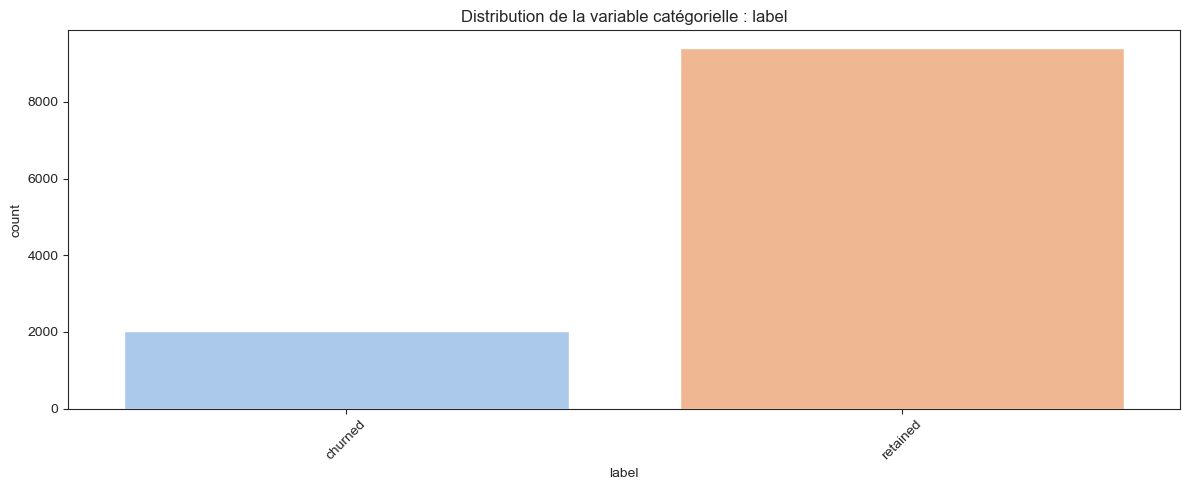

In [100]:
analyse_univariee(train_data, 'label')


On observe que la grande majorité des utilisateurs ont été **conservés** , tandis qu'une minorité significative  a **quitté** le service. Cette répartition indique un **déséquilibre de classes**, ce qui est important à prendre en compte si l'on souhaite entraîner un modèle de machine learning, car cela pourrait biaiser les prédictions en faveur de la classe majoritaire.


🔎 Analyse de la variable : sessions
------------------------------------------------------------
Médiane de sessions : 57.00


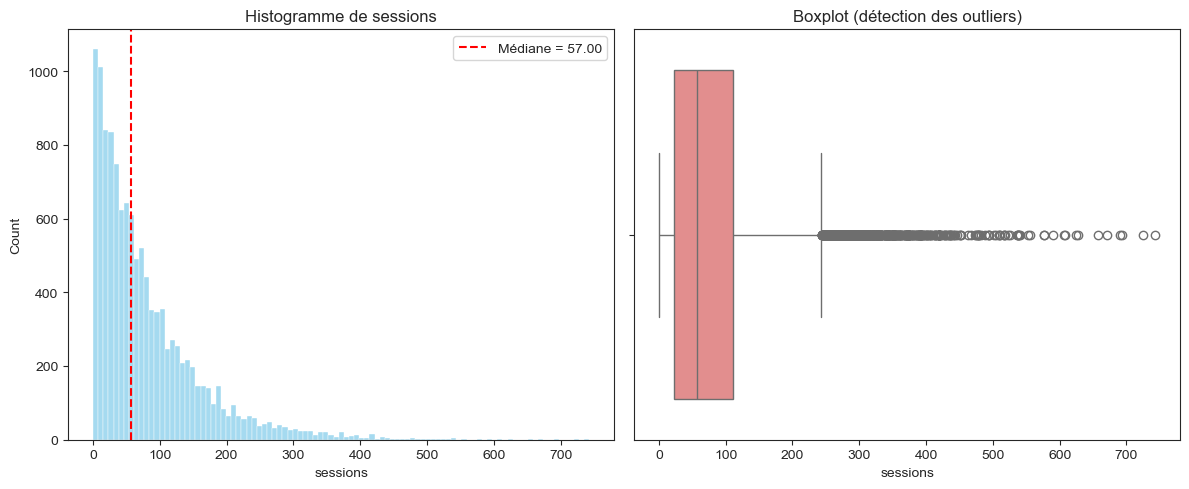

In [40]:
analyse_univariee(train_data, 'sessions')

Les graphiques montrent que la majorité des utilisateurs ont un nombre de sessions faible (entre 0 et 100), avec une distribution fortement asymétrique à droite. Le boxplot met en évidence de nombreux outliers, représentant des utilisateurs très actifs. Cette répartition indique une concentration sur peu de sessions, mais avec quelques cas extrêmes à analyser ou à traiter.


🔎 Analyse de la variable : drives
------------------------------------------------------------
Médiane de drives : 48.00


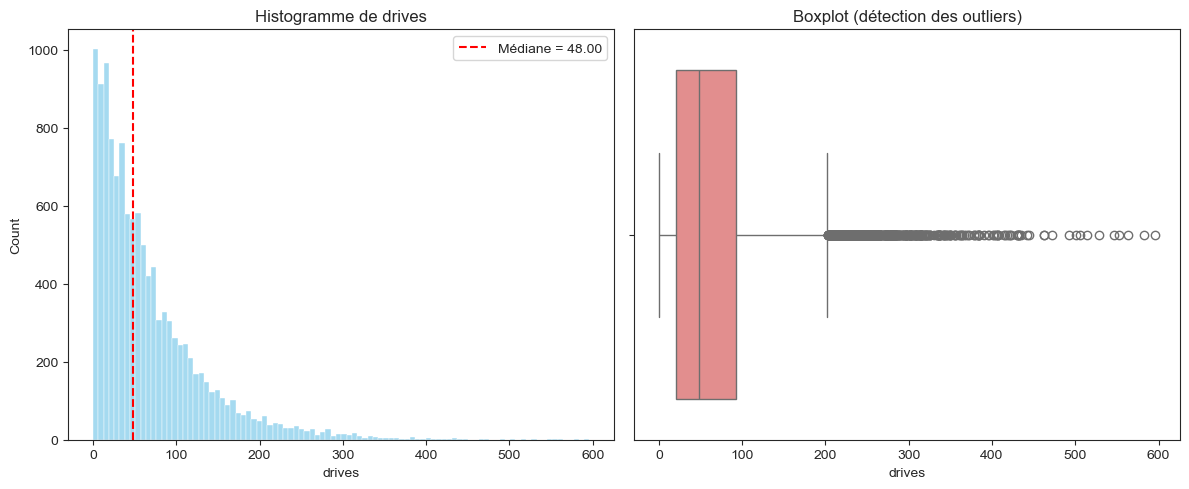

In [42]:
analyse_univariee(train_data, 'drives')

Les graphiques montrent que la majorité des drives se situent dans une plage faible à modérée (entre 0 et 300), avec une distribution probablement asymétrique à droite (queue étendue vers les valeurs élevées). Le boxplot révèle la présence de plusieurs outliers, correspondant à des drives exceptionnellement nombreux (potentiellement au-delà de 600). Cette répartition suggère que l'activité est concentrée sur un nombre limité de drives pour la plupart des cas, mais avec quelques valeurs extrêmes qui pourraient nécessiter une analyse approfondie (ex : vérification d'erreurs de mesure, segmentation des utilisateurs très actifs, ou normalisation des données).


🔎 Analyse de la variable : total_sessions
------------------------------------------------------------
Médiane de total_sessions : 159.34


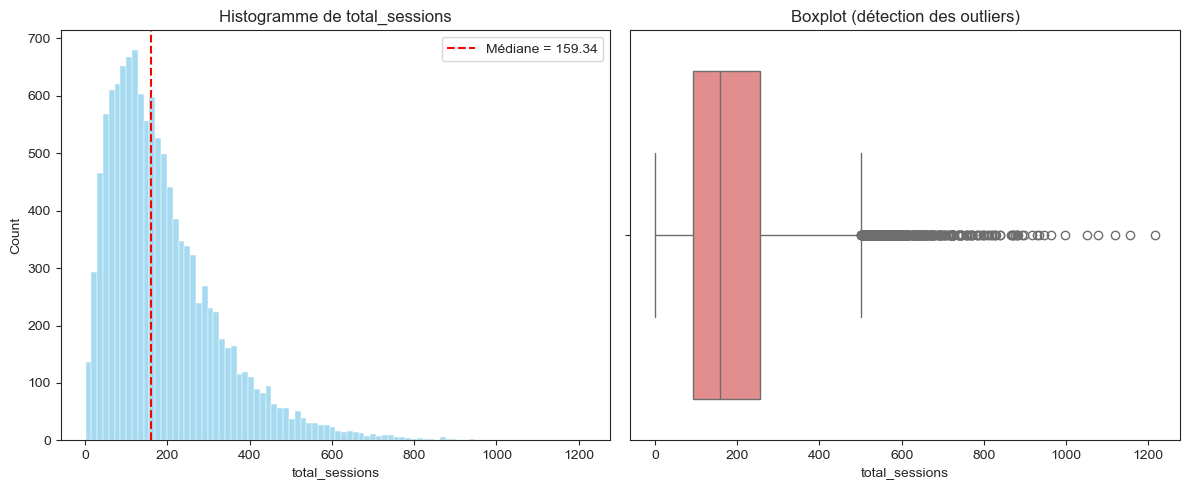

In [44]:
analyse_univariee(train_data, 'total_sessions')


La variable total_sessions présente une distribution asymétrique à droite, avec une majorité des valeurs concentrées entre 0 et 400 sessions, et une médiane de 158,59. L’histogramme montre que la plupart des utilisateurs ont un nombre de sessions relativement faible, tandis que le boxplot révèle la présence de nombreux outliers, avec certains utilisateurs atteignant plus de 1000 sessions. Cette situation suggère un comportement utilisateur globalement normal, mais avec quelques cas extrêmes qui pourraient nécessiter une analyse plus approfondie. La médiane est donc un indicateur central plus fiable que la moyenne dans ce contexte.


🔎 Analyse de la variable : n_days_after_onboarding
------------------------------------------------------------
Médiane de n_days_after_onboarding : 1750.00


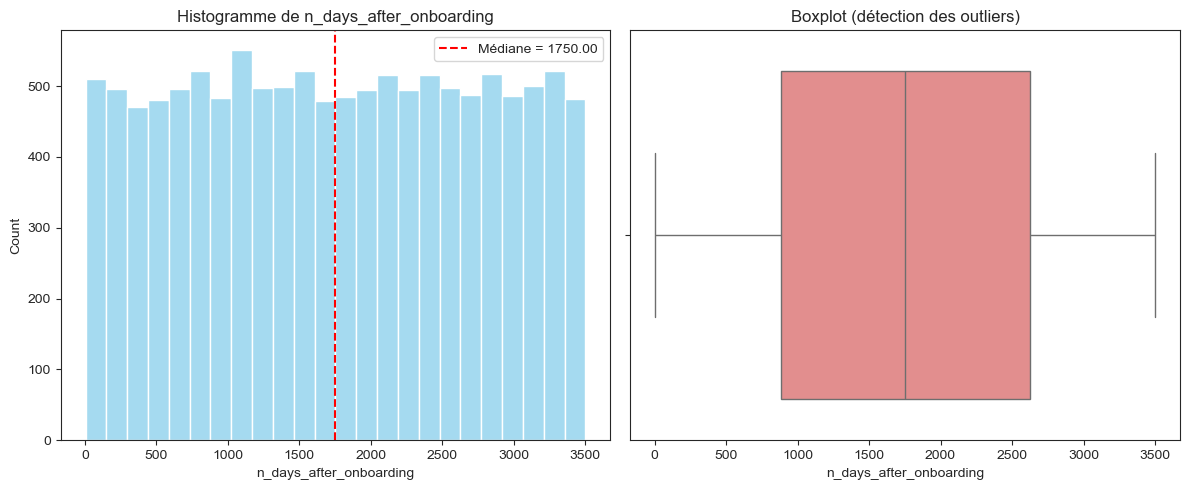

In [48]:
analyse_univariee(train_data, 'n_days_after_onboarding')

La variable n_days_after_onboarding suit une distribution relativement uniforme, comme le montre l’histogramme avec des barres de hauteur similaire sur toute la plage de valeurs. Cela indique que les utilisateurs sont répartis de manière équilibrée selon le nombre de jours depuis leur onboarding. La médiane est de 1750 jours, ce qui signifie que la moitié des utilisateurs ont été onboardés depuis moins de 1750 jours, et l’autre moitié depuis plus longtemps. Le boxplot confirme cette distribution régulière en montrant une boîte bien centrée sans outliers apparents, ce qui indique une absence de valeurs extrêmes. En résumé, cette variable est bien répartie et ne montre pas d’anomalies significatives.


🔎 Analyse de la variable : total_navigations_fav1
------------------------------------------------------------
Médiane de total_navigations_fav1 : 72.00


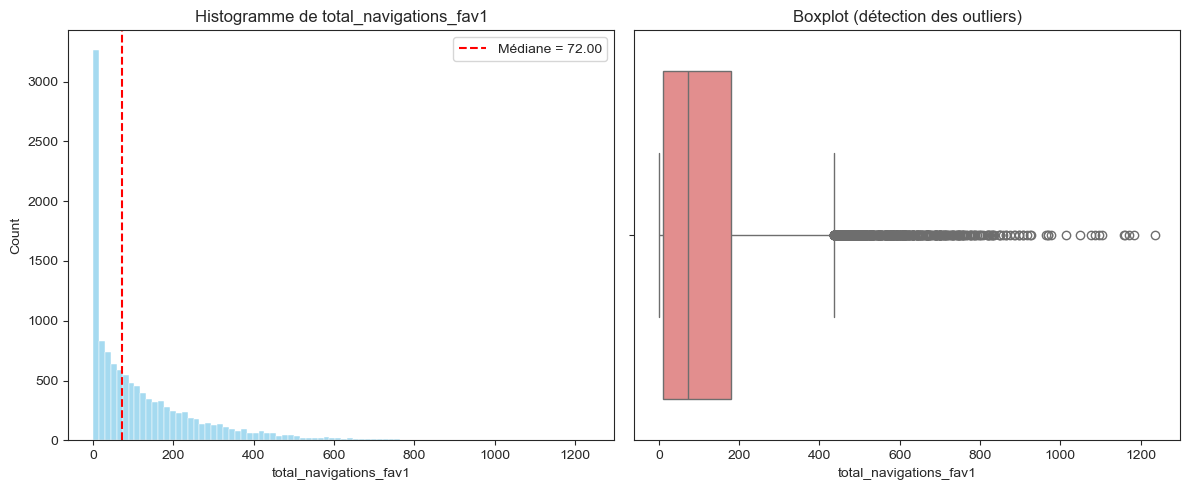

In [50]:
analyse_univariee(train_data,'total_navigations_fav1')

Les graphiques révèlent que la majorité des utilisateurs effectuent un nombre modéré de navigations favorites, avec une médiane de 72, indiquant que 50 % des utilisateurs ont moins de 73 navigations. L'histogramme montre une forte concentration des données dans les valeurs basses (probablement entre 0 et 200 navigations), tandis qu'une longue queue s'étend jusqu'à 700 , signe d'une distribution très asymétrique à droite. Le boxplot confirme cette tendance : la boîte, centrée autour de la médiane, est relativement étroite, mais de nombreux outliers sont présents au-delà de 200 navigations, avec certains cas extrêmes atteignant 700.


🔎 Analyse de la variable : total_navigations_fav2
------------------------------------------------------------
Médiane de total_navigations_fav2 : 9.00


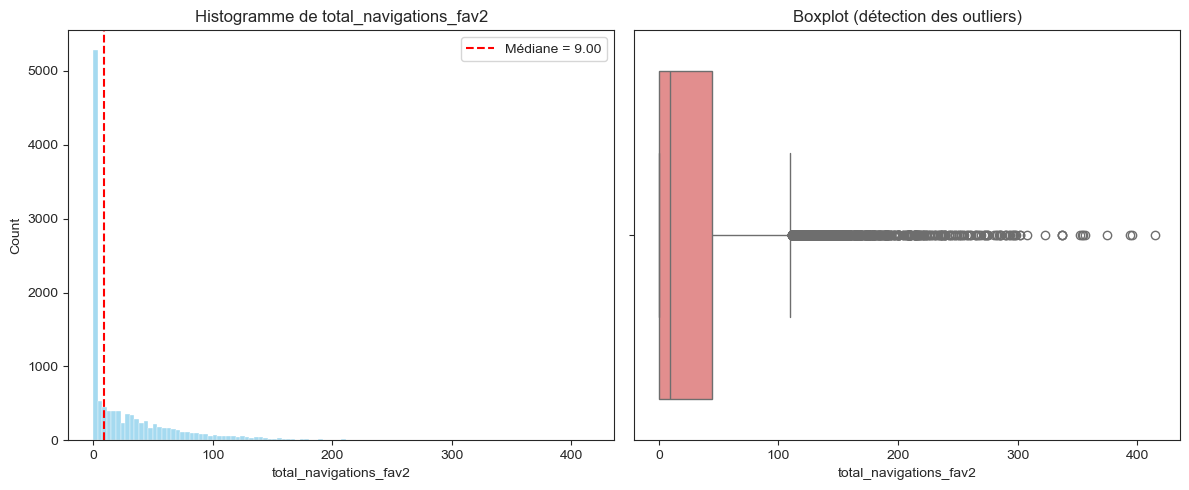

In [52]:
analyse_univariee(train_data,'total_navigations_fav2')

 La médiane très basse (9 navigations) révèle que la moitié des utilisateurs enregistrent moins de 9 favoris, avec une distribution extrêmement concentrée entre 0 et 50 navigations (histogramme montrant un pic marqué dans cette zone), tandis que le boxplot identifie des outliers atteignant jusqu'à 200 navigations, ce qui indique une utilisation marginale par la grande majorité des utilisateurs, contrastant avec quelques cas isolés d'utilisation intensive. Cette asymétrie prononcée suggère que la fonctionnalité est peu exploitée par le grand public, mais peut être cruciale pour une niche d'utilisateurs actifs.


🔎 Analyse de la variable : driven_km_drives
------------------------------------------------------------
Médiane de driven_km_drives : 3489.55


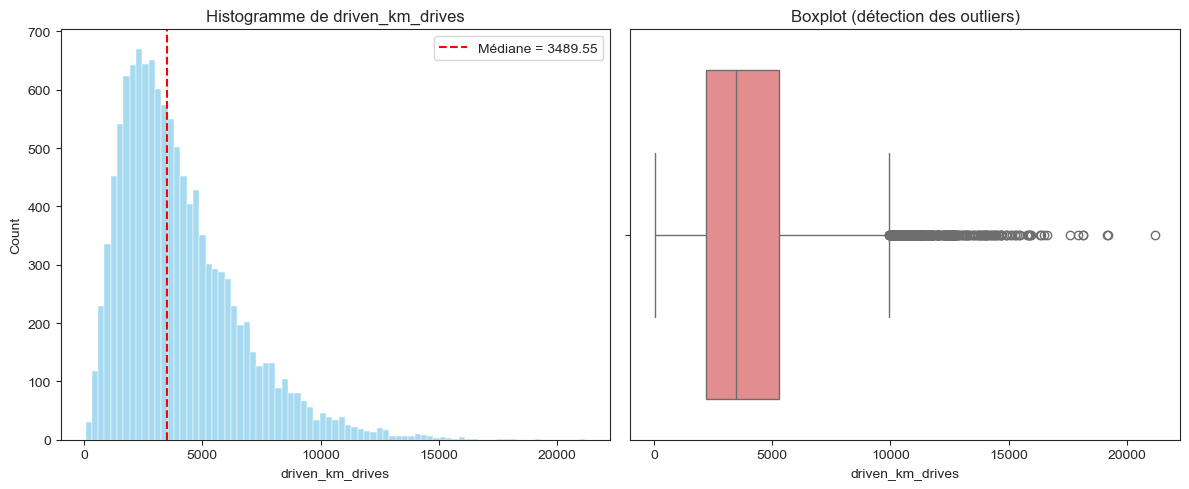

In [54]:
analyse_univariee(train_data,'driven_km_drives')

Avec une médiane à 3 489.55 km, la moitié des conducteurs parcourent moins que cette distance, révélant une distribution asymétrique où la plupart des trajets se concentrent dans les faibles et moyennes distances . Le boxplot montre cependant des valeurs extrêmes atteignant 20 000 km, indiquant la présence de quelques conducteurs parcourant des distances exceptionnellement longues par rapport à la majorité.Cette dispersion suggère des profils d'usage très variés, allant d'une utilisation occasionnelle à des comportements intensifs, potentiellement professionnels.



🔎 Analyse de la variable : duration_minutes_drives
------------------------------------------------------------
Médiane de duration_minutes_drives : 1475.97


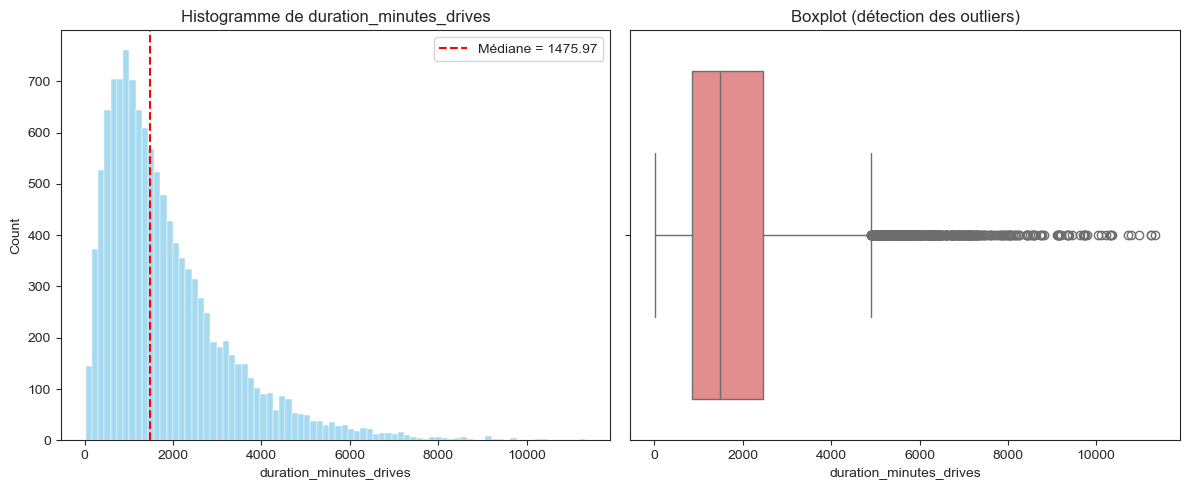

In [56]:
analyse_univariee(train_data,'duration_minutes_drives')

La médiane de 1 476 minutes (environ 24h) révèle que la moitié des trajets durent moins de cette durée, avec une distribution fortement concentrée entre 0 et 4 000 minutes (histogramme montrant un pic marqué dans cette plage). Le boxplot met en évidence des valeurs extrêmes atteignant jusqu'à 10 000 minutes (environ 7 jours), indiquant la présence de quelques trajets exceptionnellement longs, probablement liés à des usages professionnels ou spécifiques. Cette dispersion importante entre la majorité des trajets courts/moyens et quelques outliers extrêmes suggère des comportements de conduite très polarisés(usage professionnel et personnel).


🔎 Analyse de la variable : activity_days
------------------------------------------------------------
Médiane de activity_days : 16.00


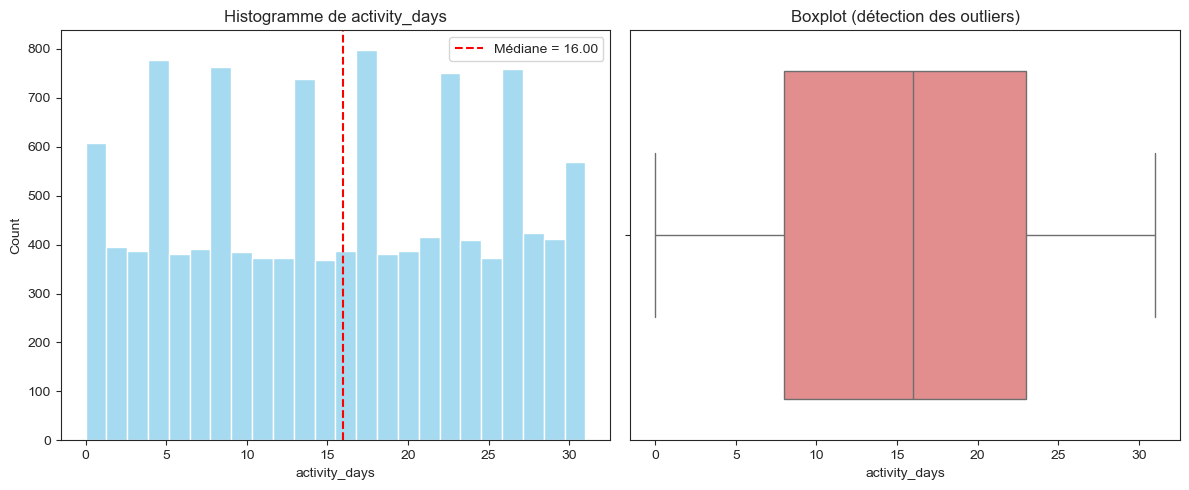

In [58]:
analyse_univariee(train_data,'activity_days')

 Avec une médiane à 16 jours, la moitié des utilisateurs sont actifs moins de 16 jours sur le mois analysé, révélant une distribution relativement équilibrée entre 0 et 30 jours (histogramme montrant une répartition progressive). Le boxplot montre l'abscence des outliers , ce qui suggère une utilisation majoritairement régulière et réaliste du service, avec une fréquence d'activité généralement comprise entre quelques jours et un mois complet.


🔎 Analyse de la variable : driving_days
------------------------------------------------------------
Médiane de driving_days : 12.00


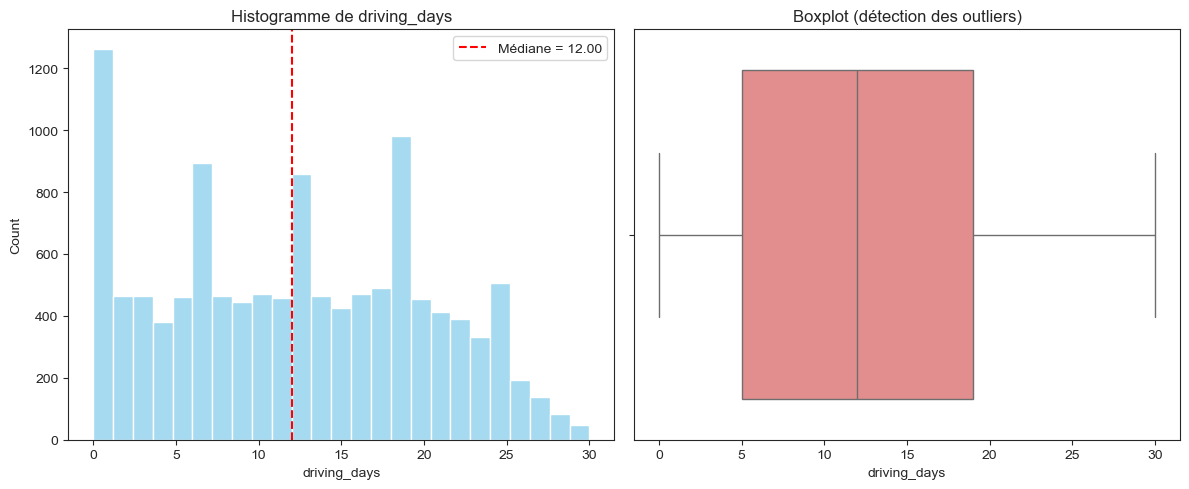

In [60]:
analyse_univariee(train_data,'driving_days')

Avec une médiane de 12 jours, la moitié des conducteurs roulent moins de 12 jours par mois, révélant une distribution relativement équilibrée mais légèrement concentrée sur la première moitié du mois (0-15 jours). L'histogramme montre une décroissance progressive après 15 jours, tandis que le boxplot (bien que mal annoté) suggère l'absence d'outliers extrêmes

In [62]:
evaluerColonne(train_data, 'device')

device
         COUNT  RATIO
device               
iPhone    7700  64.17
Android   4299  35.83





🔎 Analyse de la variable : device
------------------------------------------------------------


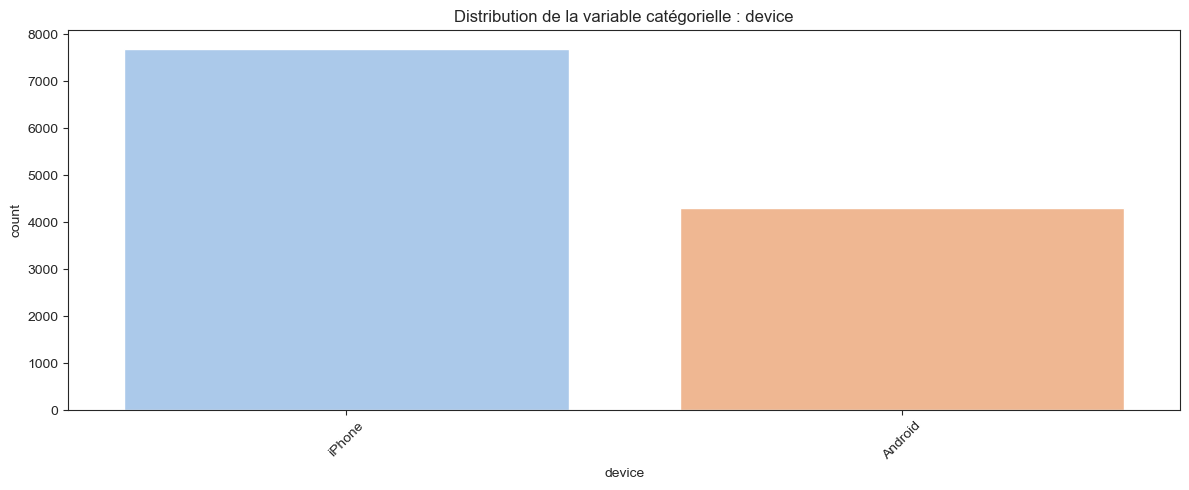

In [64]:
analyse_univariee(train_data,'device')

 Le graphique montre une nette domination des utilisateurs iPhone par rapport aux utilisateurs Android, indiquant que l'application est significativement plus populaire parmi les possesseurs d'iPhone, avec un ratio d'environ 3 à 5 fois plus d'utilisateurs iOS. Cette disparité marquée pourrait refléter soit une préférence des utilisateurs iPhone pour ce type d'application, soit des différences dans la disponibilité ou le marketing de l'application entre les deux plateformes.

 # **analyse bivariée**

L’analyse bivariée est une étape de l’analyse de données qui consiste à étudier la relation entre deux variables. Elle permet de voir si ces deux variables sont liées, et si oui, comment.

Objectifs de l’analyse bivariée :

Comparer une variable explicative avec une variable cible.

Mesurer la force et le type de relation (positive, négative, nulle).


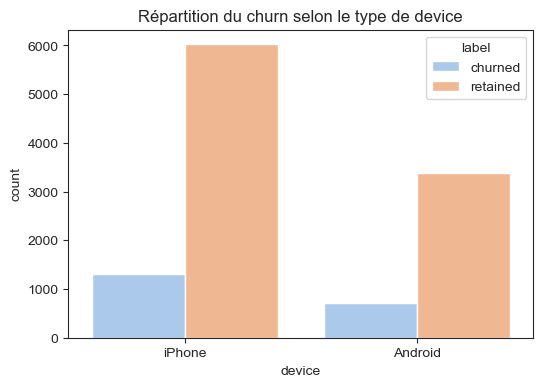

In [80]:
# Crosstab
crosstab_result=pd.crosstab(train_data["device"], train_data["label"], normalize="index")  # pourcentages
# Barplot
sns.countplot(data=train_data, x="device", hue="label",palette='pastel')
plt.title("Répartition du churn selon le type de device")
plt.show()

On remarque les utilisateurs iPhone sont plus nombreux et présentent aussi plus de cas de churn en valeur absolue.
Cependant, pour conclure sur l’impact du device sur le churn, le churn est présent sur les deux types de device, mais en valeur brute, plus élevé chez les utilisateurs iPhone.

In [82]:
print(crosstab_result)

label    churned  retained
device                    
Android     0.18      0.82
iPhone      0.18      0.82


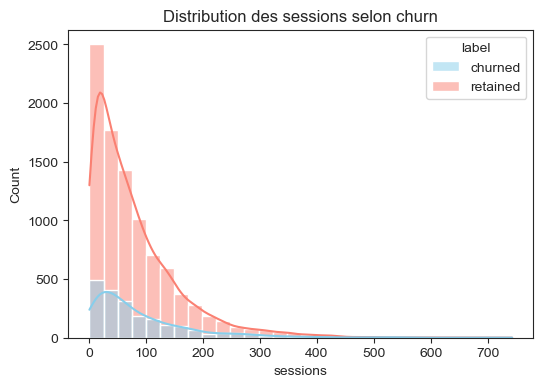

In [84]:
sns.histplot(data=train_data, x='sessions', hue='label', kde=True,palette=['skyblue', 'salmon'], bins=30)
plt.title("Distribution des sessions selon churn")
plt.show()

Ce graphique montre la distribution du nombre de sessions selon le statut de churn. On observe que les utilisateurs churned ont majoritairement un faible nombre de sessions. En revanche, les utilisateurs retained sont plus nombreux et présentent une plus grande diversité de sessions, avec une longue traîne. Cela suggère que la fréquence d’utilisation de l’app (via les sessions) est un facteur clé de fidélisation : plus les utilisateurs sont actifs, moins ils risquent de churner.

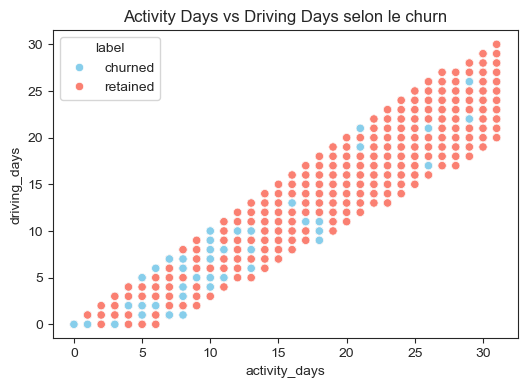

In [64]:
sns.scatterplot(x='activity_days', y='driving_days', hue='label',palette=['skyblue', 'salmon'], data=train_data)
plt.title("Activity Days vs Driving Days selon le churn")
plt.show()

Il existe une relation linéaire entre les jours d'activité (activity_days) et les jours de conduite (driving_days) : plus un utilisateur est actif, plus il conduit fréquemment (conduire ≠ être actif ,on peut être actif sans conduire). Les utilisateurs churned (en orange) affichent généralement moins de jours de conduite pour un nombre équivalent de jours d'activité, tandis que les utilisateurs retained (en bleu) se concentrent dans la zone où les deux valeurs sont élevées, ce qui indique un engagement plus fort.

Cela suggère que la fréquence de conduite est un indicateur clé de rétention, Hypothèse possible  :

-Les utilisateurs qui utilisent l’app sans conduire souvent (activité passive) sont plus susceptibles de churn.

-Les utilisateurs qui conduisent régulièrement sont moins susceptibles de churn.

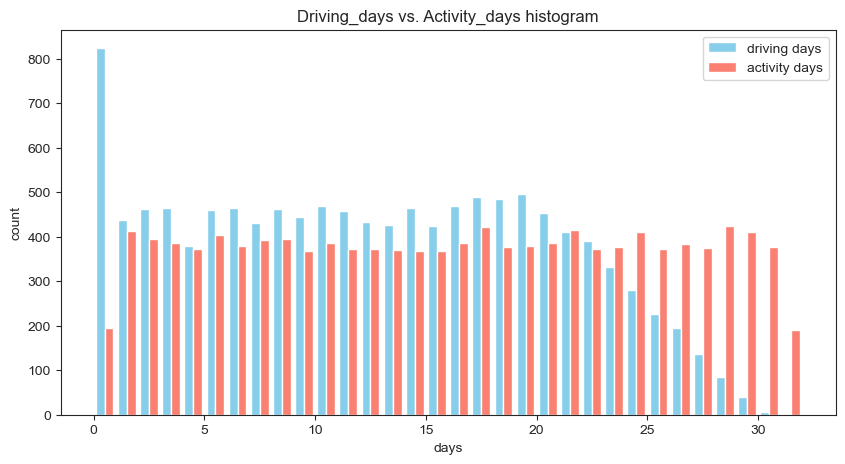

In [78]:
# Histogram
plt.figure(figsize=(10,5))
label=['driving days', 'activity days']
plt.hist([train_data['driving_days'], train_data['activity_days']],color=['skyblue', 'salmon'], bins=range(0,33), label = label)
plt.title('Driving_days vs. Activity_days histogram')
plt.xlabel('days')
plt.ylabel('count')
plt.legend()
plt.show()

De nombreux utilisateurs ouvrent l’app sans conduire, comme le montre le pic de jours sans conduite driving_days = 0. L’activité reste stable pour les jours élevés, suggérant un usage passif. Plus d'utilisateurs consultent l'application sans conduire que ceux totalement inactifs, peut-être pour consulter les temps de trajet, vérifier un itinéraire, changer les paramètres, ou même par erreur, ce qui indique un usage alternatif.Un faible ratio driving_days / activity_days pourrait signaler un risque de churn.

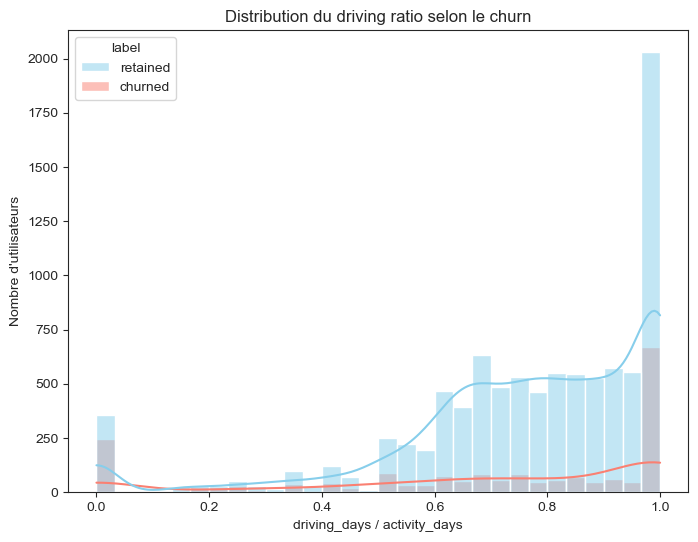

In [70]:

# Création d'un DataFrame temporaire juste pour le plot
ratio_data = train_data.copy()
ratio_data = ratio_data[ratio_data["activity_days"] > 0]  # éviter division par 0
ratio_data["driving_ratio_tmp"] = ratio_data["driving_days"] / ratio_data["activity_days"]

plt.figure(figsize=(8,6))
sns.histplot(data=ratio_data, x="driving_ratio_tmp", hue="label",palette=['skyblue', 'salmon'], kde=True, bins=30)
plt.title("Distribution du driving ratio selon le churn")
plt.xlabel("driving_days / activity_days")
plt.ylabel("Nombre d'utilisateurs")
plt.show()


* Utilisateurs retained (fidèles) :
La grande majorité d’entre eux a un driving_ratio proche de 1.0.

Ça veut dire que quand ils sont actifs, ils utilisent vraiment l'app pour conduire.

Ils sont aussi nombreux dans les valeurs intermédiaires (entre 0.4 et 0.9), ce qui montre un engagement partiel mais régulier.

* Utilisateurs churned (perdus) :
Ils sont plus concentrés autour de 0.0 → donc actifs sans jamais vraiment conduire.

Très peu de churned atteignent des ratios proches de 1.0.

Cela suggère qu'ils ouvrent l’app sans forcément en tirer un usage réel (comme la conduite).

Le pic orange au tout début (vers 0) montre une zone à risque de churn important.

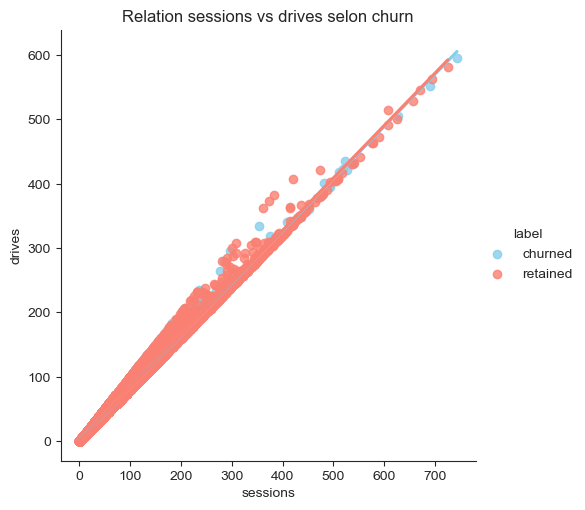

In [40]:
sns.lmplot(x='sessions', y='drives', hue='label',palette=['skyblue', 'salmon'], data=train_data)
plt.title("Relation sessions vs drives selon churn")
plt.show()

Il y a une corrélation forte et logique entre le nombre de sessions et de drives.

Mais cette relation n’est pas un bon prédicteur de churn à elle seule, car les deux groupes se superposent fortement.

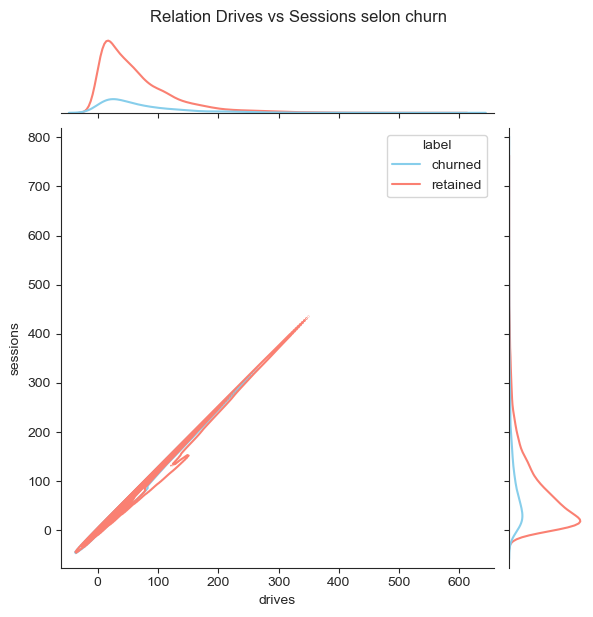

In [42]:
sns.jointplot(data=train_data, x='drives', y='sessions', hue='label',palette=['skyblue', 'salmon'], kind='kde')
plt.suptitle("Relation Drives vs Sessions selon churn", y=1.02)
plt.show()

Ce graphique montre une forte corrélation positive entre le nombre de sessions et de drives : plus un utilisateur a de sessions, plus il effectue de drives. On observe que les utilisateurs churned se concentrent majoritairement dans les faibles volumes d’activité, tandis que les utilisateurs retained ont des sessions et drives plus élevés. Cela indique que l’engagement (via les sessions et drives) joue un rôle clé dans la rétention des utilisateurs.

In [46]:
train_data['session_ratio'] = train_data['sessions'] / train_data['total_sessions']

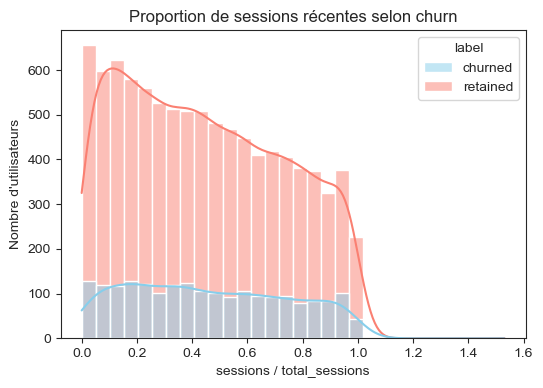

In [48]:
sns.histplot(data=train_data, x='session_ratio', hue='label',palette=['skyblue', 'salmon'], kde=True, bins=30)
plt.title("Proportion de sessions récentes selon churn")
plt.xlabel("sessions / total_sessions")
plt.ylabel("Nombre d'utilisateurs")
plt.show()

Ce graphique montre la répartition des utilisateurs en fonction de la proportion de leurs sessions récentes (sessions récentes / total des sessions) et leur statut de churn. On observe que les utilisateurs churned sont plus nombreux dans les faibles proportions (ex. < 0.2), ce qui indique qu’ils étaient moins actifs récemment par rapport à leur activité passée. À l’inverse, les utilisateurs retained ont généralement une proportion plus élevée de sessions récentes, suggérant une utilisation régulière et continue de l’app. Autrement dit, une activité récente élevée est fortement corrélée à la rétention, ce qui en fait un excellent indicateur de churn potentiel.

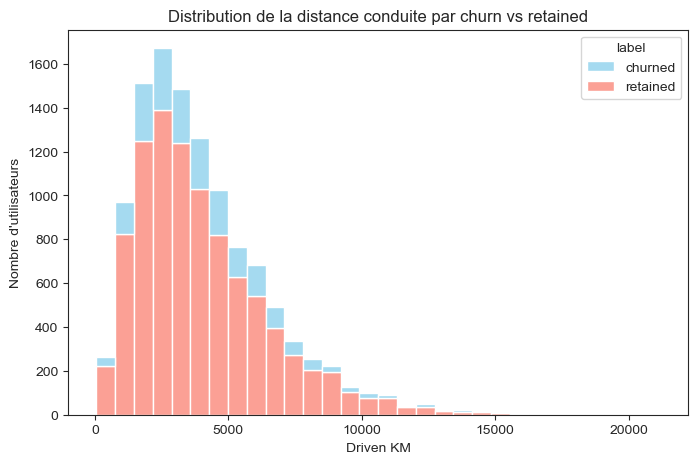

In [50]:
plt.figure(figsize=(8, 5))
sns.histplot(data=train_data, x='driven_km_drives', hue='label', bins=30,palette=['skyblue', 'salmon'], kde=False, multiple='stack')
plt.title("Distribution de la distance conduite par churn vs retained")
plt.xlabel("Driven KM")
plt.ylabel("Nombre d'utilisateurs")
plt.show()

On observe que les utilisateurs qui parcourent peu de kilomètres (surtout < 4000 km) sont plus susceptibles de churner.À l’inverse, ceux qui parcourent beaucoup de kilomètres restent généralement fidèles à l’application.

càd,la distance parcourue (Driven KM) est donc un facteur important lié à l’attrition.

Cela suggère que l'engagement via l’usage actif de l'app (plus de trajets, plus de km) réduit le risque de churn.Il faut donc surveiller les utilisateurs à faible usage et mettre en place des actions pour les réengager.

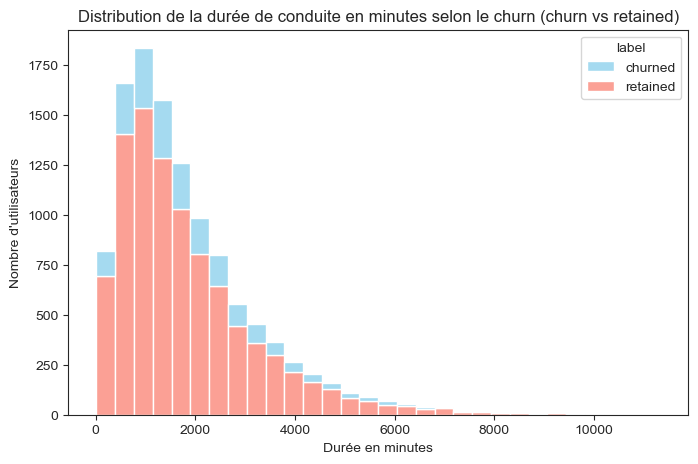

In [52]:
plt.figure(figsize=(8, 5))
sns.histplot(data=train_data, x='duration_minutes_drives', hue='label', bins=30,palette=['skyblue', 'salmon'], kde=False, multiple='stack')
plt.title("Distribution de la durée de conduite en minutes selon le churn (churn vs retained)")
plt.xlabel("Durée en minutes")
plt.ylabel("Nombre d'utilisateurs")
plt.show()

On remarque que plus un utilisateur passe de temps à conduire avec Waze, moins il a de chances de churner.Comme pour la distance parcourue (driven_km_drives), la durée de conduite est un bon indicateur d’engagement.

Les utilisateurs avec une durée < 2000 minutes sont à haut risque d’attrition. Il faut donc surveiller et cibler les utilisateurs avec une faible durée cumulée pour des campagnes de rétention.



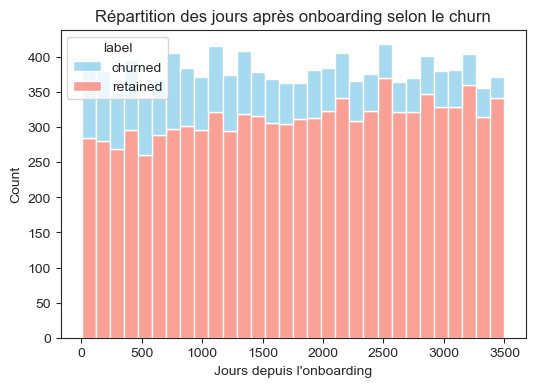

In [54]:
sns.histplot(data=train_data, x='n_days_after_onboarding', hue='label',palette=['skyblue', 'salmon'], multiple='stack', bins=30)
plt.title("Répartition des jours après onboarding selon le churn")
plt.xlabel("Jours depuis l'onboarding")
plt.show()

La majorité des cas d’attrition se produisent dans les premières années après l’onboarding. Les utilisateurs qui restent engagés au-delà de cette période montrent un comportement de fidélisation plus fort. Cela suggère qu’un accompagnement renforcé dans les premières phases de l’usage de l’app (ex. : onboarding, rappels, contenus personnalisés) pourrait aider à réduire l’attrition précoce.

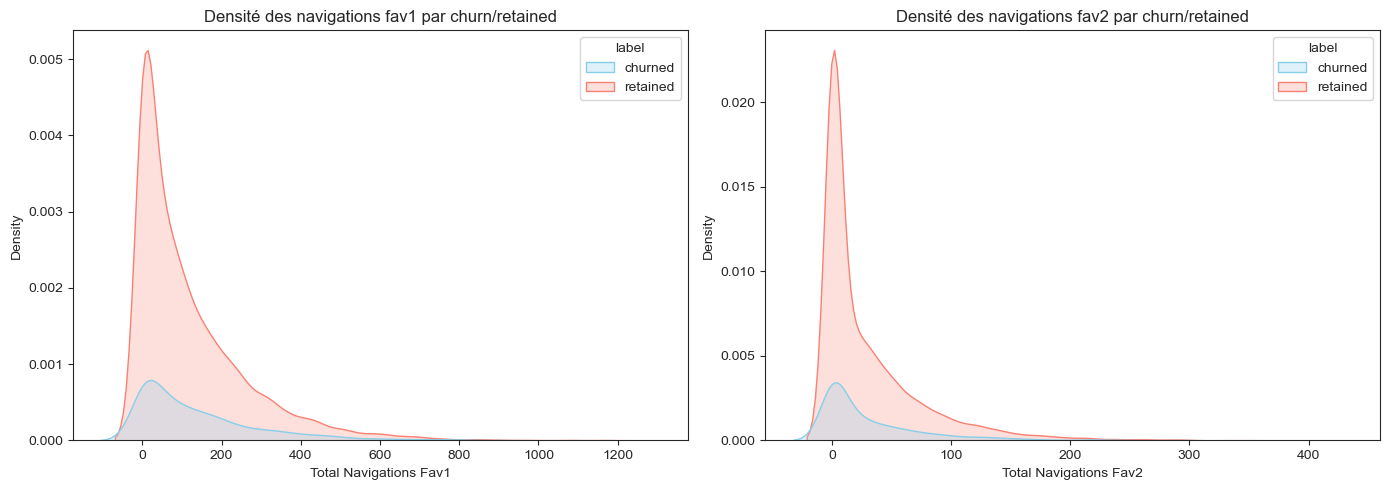

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE pour total_navigations_fav1
sns.kdeplot(data=train_data, x='total_navigations_fav1', hue='label',palette=['skyblue', 'salmon'], fill=True, ax=axes[0])
axes[0].set_title("Densité des navigations fav1 par churn/retained")
axes[0].set_xlabel("Total Navigations Fav1")

# KDE pour total_navigations_fav2
sns.kdeplot(data=train_data, x='total_navigations_fav2', hue='label',palette=['skyblue', 'salmon'], fill=True, ax=axes[1])
axes[1].set_title("Densité des navigations fav2 par churn/retained")
axes[1].set_xlabel("Total Navigations Fav2")

plt.tight_layout()
plt.show()


On remarque que :
-Les utilisateurs qui utilisent fréquemment leurs trajets favoris (surtout fav1) sont plus susceptibles d’être retenus.

-Le manque d’utilisation de ces chemins favoris est un indicateur possible d’attrition.

-Le trajet fav1 a une influence plus marquée que fav2 — probablement parce qu’il est plus utilisé ou plus important dans l’usage quotidien de l’app.

L’analyse montre que l’usage fréquent des trajets favoris, en particulier fav1, est lié à une plus grande fidélité. Une faible utilisation de ces itinéraires pourrait indiquer un désintérêt progressif, menant à l’attrition.

 # **6. Corrélation**

Dans cette partie, nous analysons les relations linéaires entre les variables numériques via une matrice de corrélation. Contrairement à l'analyse bivariée précédente qui exploite les liens entre chaque variable et la cible, ici nous nous concentrons uniquement sur les interactions entre les variables explicatives numériques.

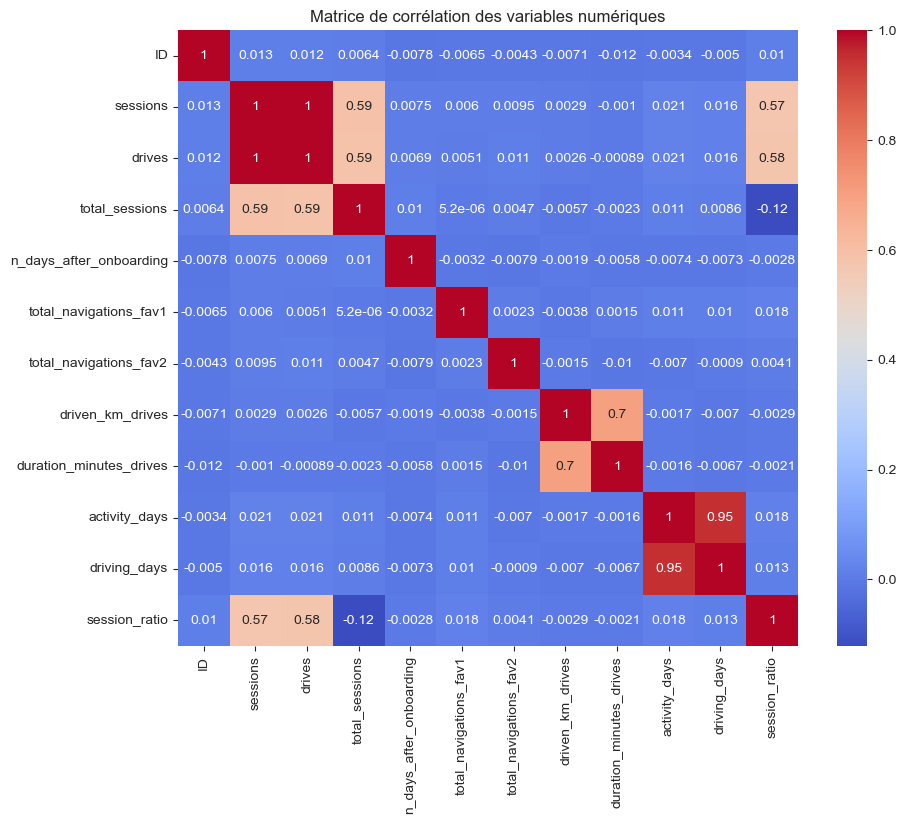

In [92]:
corr_matrix = train_data.select_dtypes(include='number').corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Matrice de corrélation des variables numériques")
plt.show()

La matrice de corrélation montre que la majorité des variables numériques sont faiblement corrélées entre elles, ce qui indique qu'elles apportent des informations complémentaires. On note néanmoins quelques fortes corrélations positives, notamment entre activity_days et driving_days (0.95), ainsi qu'entre driven_km_drives et duration_minutes_drives (0.7), ce qui est cohérent avec le comportement attendu des utilisateurs. De plus, les variables liées à l’utilisation de l’application comme sessions, drives et total_sessions présentent des corrélations modérées autour de 0.59. Ces observations peuvent orienter la sélection ou la transformation des variables dans les étapes ultérieures de l’analyse.

